In [139]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [140]:
data = pd.read_excel("creditcard.xls")

In [141]:
data

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29996,29996,220000,1,3,1,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29997,29997,150000,1,3,2,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29998,29998,30000,1,2,2,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29999,29999,80000,1,3,1,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


In [142]:
df = pd.DataFrame(data)

In [143]:
df

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29996,29996,220000,1,3,1,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29997,29997,150000,1,3,2,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29998,29998,30000,1,2,2,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29999,29999,80000,1,3,1,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


In [144]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30001 entries, 0 to 30000
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  30001 non-null  object
 1   X1          30001 non-null  object
 2   X2          30001 non-null  object
 3   X3          30001 non-null  object
 4   X4          30001 non-null  object
 5   X5          30001 non-null  object
 6   X6          30001 non-null  object
 7   X7          30001 non-null  object
 8   X8          30001 non-null  object
 9   X9          30001 non-null  object
 10  X10         30001 non-null  object
 11  X11         30001 non-null  object
 12  X12         30001 non-null  object
 13  X13         30001 non-null  object
 14  X14         30001 non-null  object
 15  X15         30001 non-null  object
 16  X16         30001 non-null  object
 17  X17         30001 non-null  object
 18  X18         30001 non-null  object
 19  X19         30001 non-null  object
 20  X20         30001

In [145]:
df.isnull()

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29996,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
29997,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
29998,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
29999,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [146]:
df.isnull().sum()

Unnamed: 0    0
X1            0
X2            0
X3            0
X4            0
X5            0
X6            0
X7            0
X8            0
X9            0
X10           0
X11           0
X12           0
X13           0
X14           0
X15           0
X16           0
X17           0
X18           0
X19           0
X20           0
X21           0
X22           0
X23           0
Y             0
dtype: int64

In [147]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
29996    False
29997    False
29998    False
29999    False
30000    False
Length: 30001, dtype: bool

In [148]:
df.head(10)

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
6,6,50000,1,1,2,37,0,0,0,0,...,19394,19619,20024,2500,1815,657,1000,1000,800,0
7,7,500000,1,1,2,29,0,0,0,0,...,542653,483003,473944,55000,40000,38000,20239,13750,13770,0
8,8,100000,2,2,2,23,0,-1,-1,0,...,221,-159,567,380,601,0,581,1687,1542,0
9,9,140000,2,3,1,28,0,0,2,0,...,12211,11793,3719,3329,0,432,1000,1000,1000,0


In [149]:
df.tail()

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
29996,29996,220000,1,3,1,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29997,29997,150000,1,3,2,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29998,29998,30000,1,2,2,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29999,29999,80000,1,3,1,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1
30000,30000,50000,1,2,1,46,0,0,0,0,...,36535,32428,15313,2078,1800,1430,1000,1000,1000,1


In [150]:
df.shape

(30001, 25)

In [151]:
df.describe()

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
count,30001,30001,30001,30001,30001,30001,30001,30001,30001,30001,...,30001,30001,30001,30001,30001,30001,30001,30001,30001,30001
unique,30001,82,3,8,5,57,12,12,12,12,...,21549,21011,20605,7944,7900,7519,6938,6898,6940,3
top,ID,50000,2,2,2,29,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
freq,1,3365,18112,14030,15964,1605,14737,15730,15764,16455,...,3195,3506,4020,5249,5396,5968,6408,6703,7173,23364


In [152]:
print(df.isnull().sum())

Unnamed: 0    0
X1            0
X2            0
X3            0
X4            0
X5            0
X6            0
X7            0
X8            0
X9            0
X10           0
X11           0
X12           0
X13           0
X14           0
X15           0
X16           0
X17           0
X18           0
X19           0
X20           0
X21           0
X22           0
X23           0
Y             0
dtype: int64


In [153]:
data.columns = data.iloc[0].astype(str).str.strip()
df = data.iloc[1:].reset_index(drop=True)

In [154]:
df = df.drop(columns= [""], errors = "ignore")
df = df.loc[:, ~df.columns.str.match(r"^Unamed")]
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [155]:
df.fillna

<bound method NDFrame.fillna of 0         ID LIMIT_BAL SEX EDUCATION MARRIAGE AGE PAY_0 PAY_2 PAY_3 PAY_4  \
0          1     20000   2         2        1  24     2     2    -1    -1   
1          2    120000   2         2        2  26    -1     2     0     0   
2          3     90000   2         2        2  34     0     0     0     0   
3          4     50000   2         2        1  37     0     0     0     0   
4          5     50000   1         2        1  57    -1     0    -1     0   
...      ...       ...  ..       ...      ...  ..   ...   ...   ...   ...   
29995  29996    220000   1         3        1  39     0     0     0     0   
29996  29997    150000   1         3        2  43    -1    -1    -1    -1   
29997  29998     30000   1         2        2  37     4     3     2    -1   
29998  29999     80000   1         3        1  41     1    -1     0     0   
29999  30000     50000   1         2        1  46     0     0     0     0   

0      ... BILL_AMT4 BILL_AMT5 BILL_AMT6 PA

In [156]:
df.drop_duplicates

<bound method DataFrame.drop_duplicates of 0         ID LIMIT_BAL SEX EDUCATION MARRIAGE AGE PAY_0 PAY_2 PAY_3 PAY_4  \
0          1     20000   2         2        1  24     2     2    -1    -1   
1          2    120000   2         2        2  26    -1     2     0     0   
2          3     90000   2         2        2  34     0     0     0     0   
3          4     50000   2         2        1  37     0     0     0     0   
4          5     50000   1         2        1  57    -1     0    -1     0   
...      ...       ...  ..       ...      ...  ..   ...   ...   ...   ...   
29995  29996    220000   1         3        1  39     0     0     0     0   
29996  29997    150000   1         3        2  43    -1    -1    -1    -1   
29997  29998     30000   1         2        2  37     4     3     2    -1   
29998  29999     80000   1         3        1  41     1    -1     0     0   
29999  30000     50000   1         2        1  46     0     0     0     0   

0      ... BILL_AMT4 BILL_AMT5 B

<Axes: xlabel='0'>

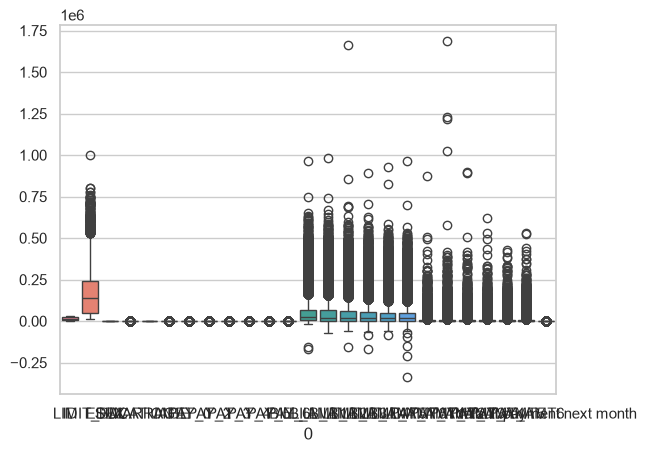

In [157]:
sns.boxplot(data=df)

In [158]:
outlier_cols = [
    'LIMIT_BAL',
    'AGE',
    'BILL_AMT1',
    'BILL_AMT2',
    'BILL_AMT3',
    'BILL_AMT4',
    'BILL_AMT5',
    'BILL_AMT6',
    'PAY_AMT1',
    'PAY_AMT2',
    'PAY_AMT3',
    'PAY_AMT4',
    'PAY_AMT5',
    'PAY_AMT6'
]

outlier_cols = [col for col in outlier_cols if col in df.columns]

In [159]:
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower=lower_limit, upper=upper_limit)

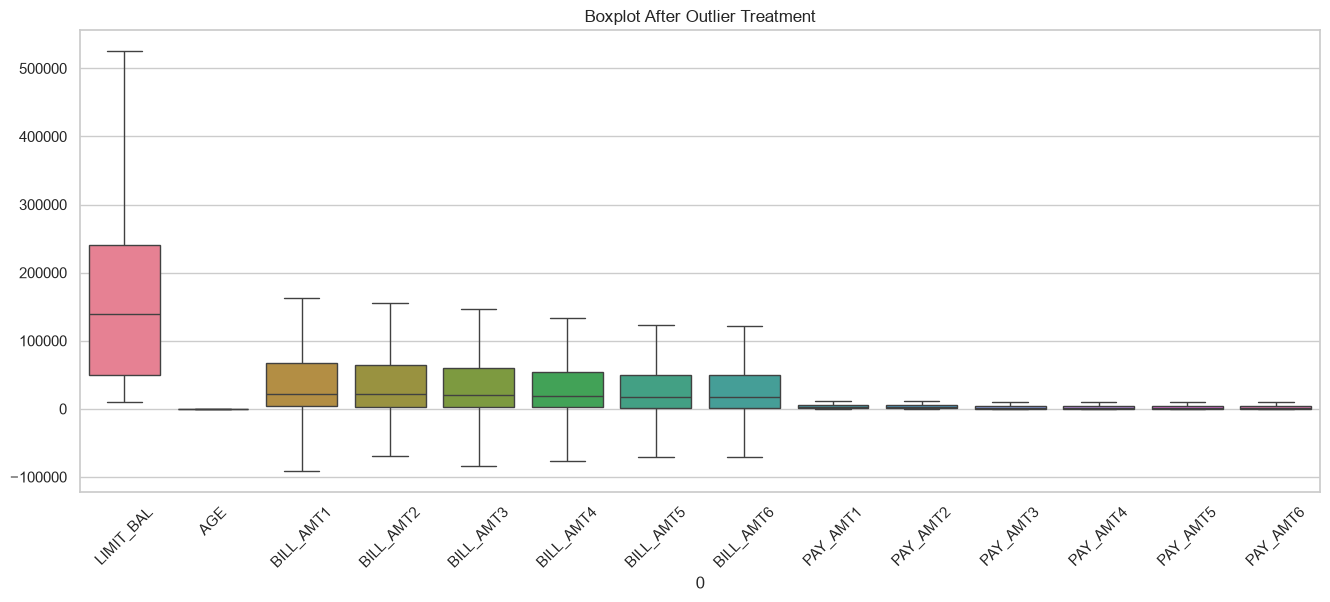

In [160]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 6))
sns.boxplot(data=df[outlier_cols])

plt.xticks(rotation=45)
plt.title("Boxplot After Outlier Treatment")
plt.show()

In [161]:
target_column = "default payment next month"

# Categorical columns represented by numeric category codes in this dataset.
categorical_columns = [
    column for column in ["SEX", "EDUCATION", "MARRIAGE"]
    if column in df.columns
]

print("Categorical predictor columns:", categorical_columns)

Categorical predictor columns: ['SEX', 'EDUCATION', 'MARRIAGE']


In [162]:
# ID is an identifier, so it is excluded from the predictors.
X = df.drop(
    columns=[target_column, "ID"],
    errors="ignore"
)

y = df[target_column].astype(int)

print("Independent variables (X):", X.shape)
print("Dependent variable (y):", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Independent variables (X): (30000, 23)
Dependent variable (y): (30000,)

Target classes:
default payment next month
0    23364
1     6636
Name: count, dtype: int64


In [163]:
# Rename the target and PAY_0 column for easier reference.
df = df.rename(columns={
    "default payment next month": "default_payment_next_month",
    "PAY_0": "PAY_1"
})

X = X.rename(columns={"PAY_0": "PAY_1"})
y.name = "default_payment_next_month"

print("Updated column names:")
print(df.columns.tolist())

Updated column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default_payment_next_month']


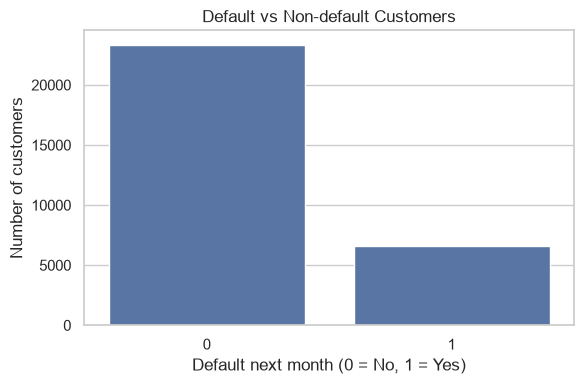

In [164]:
# Visualization 1: Target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="default_payment_next_month")
plt.title("Default vs Non-default Customers")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

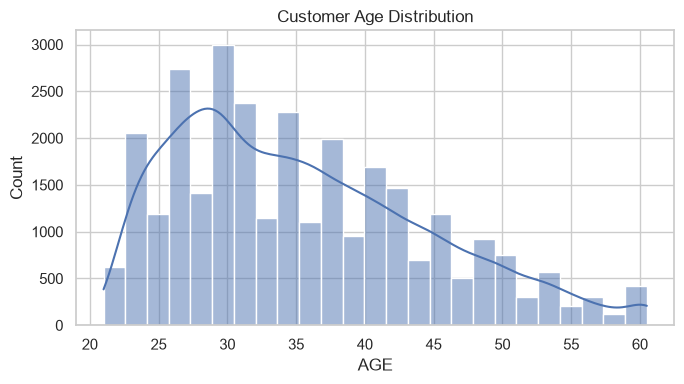

In [165]:
# Visualization 2: Customer age distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="AGE", bins=25, kde=True)
plt.title("Customer Age Distribution")
plt.tight_layout()
plt.show()

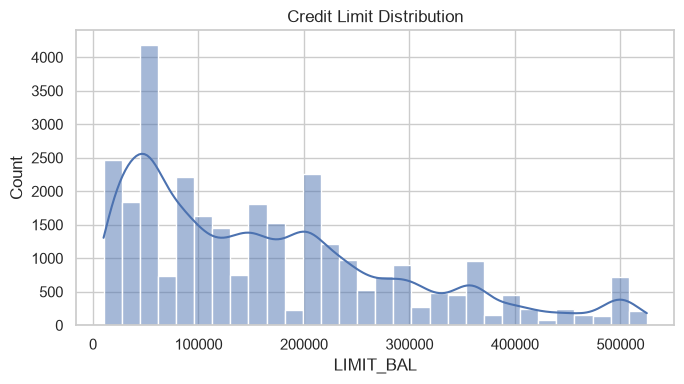

In [166]:
# Visualization 3: Credit limit distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="LIMIT_BAL", bins=30, kde=True)
plt.title("Credit Limit Distribution")
plt.tight_layout()
plt.show()

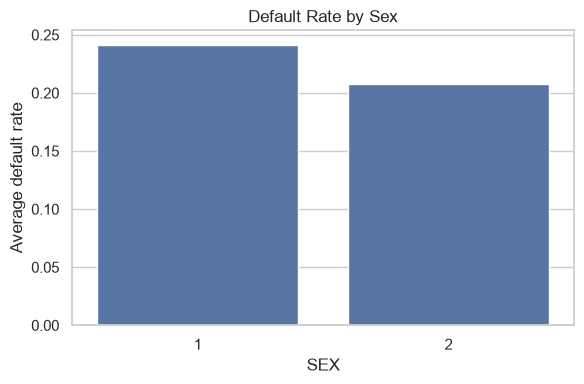

In [167]:
# Visualization 4: Default rate by sex
plt.figure(figsize=(6, 4))
sns.barplot(
    data=df,
    x="SEX",
    y="default_payment_next_month",
    errorbar=None
)
plt.title("Default Rate by Sex")
plt.ylabel("Average default rate")
plt.tight_layout()
plt.show()


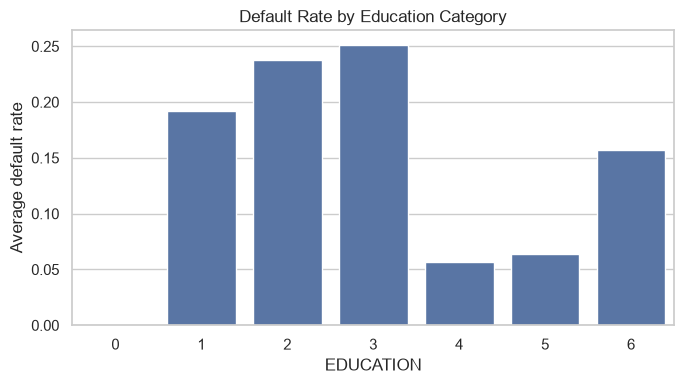

In [168]:
# Visualization 5: Default rate by education category
plt.figure(figsize=(7, 4))
sns.barplot(
    data=df,
    x="EDUCATION",
    y="default_payment_next_month",
    errorbar=None
)
plt.title("Default Rate by Education Category")
plt.ylabel("Average default rate")
plt.tight_layout()
plt.show()

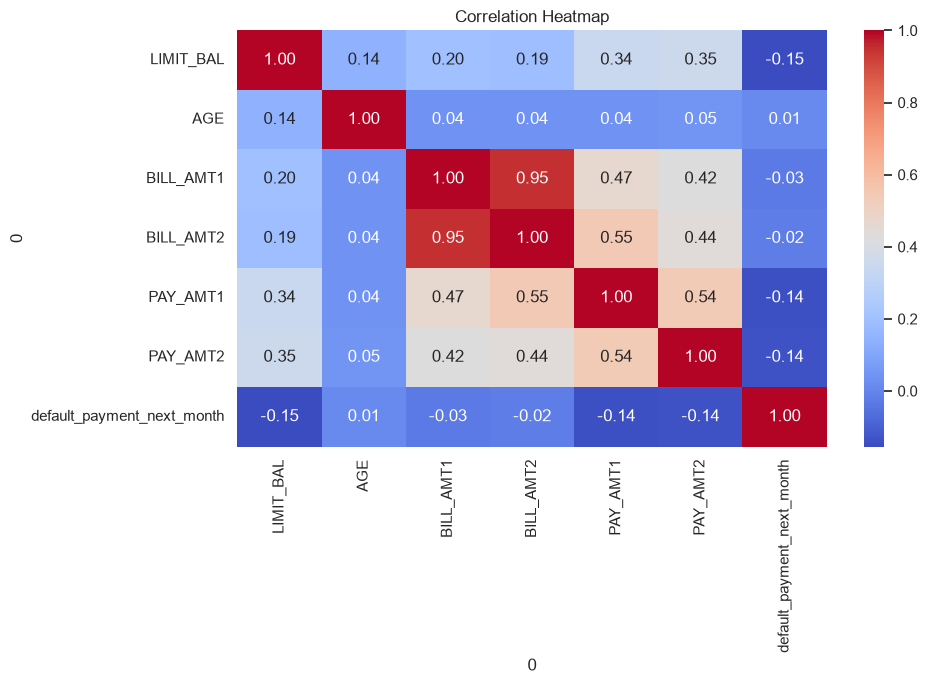

In [169]:
# Visualization 6: Correlation heatmap
correlation_columns = [
    "LIMIT_BAL", "AGE", "BILL_AMT1", "BILL_AMT2",
    "PAY_AMT1", "PAY_AMT2", "default_payment_next_month"
]
correlation_columns = [
    column for column in correlation_columns if column in df.columns
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[correlation_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [170]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (24000, 23)
Testing features: (6000, 23)

Training target distribution:
default_payment_next_month
0    0.779
1    0.221
Name: proportion, dtype: float64

Testing target distribution:
default_payment_next_month
0    0.779
1    0.221
Name: proportion, dtype: float64


In [171]:
selector = SelectKBest(score_func=f_classif, k=20)

X_new = selector.fit_transform(X, y)

In [172]:
selected_features = X.columns[selector.get_support()]

print("Selected Features:")
print(selected_features)

Selected Features:
Index(['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'PAY_1', 'PAY_2', 'PAY_3',
       'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
       'BILL_AMT4', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5',
       'PAY_AMT6'],
      dtype='str', name=0)


In [173]:
feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'Score': selector.scores_,
    'Selected': selector.get_support()
})

feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

print(feature_scores)

      Feature        Score  Selected
5       PAY_1  3537.714970      True
6       PAY_2  2239.169136      True
7       PAY_3  1757.466444      True
8       PAY_4  1476.845967      True
9       PAY_5  1304.591176      True
10      PAY_6  1085.402485      True
0   LIMIT_BAL   732.399871      True
17   PAY_AMT1   630.195082      True
18   PAY_AMT2   597.085819      True
19   PAY_AMT3   472.764309      True
22   PAY_AMT6   398.873802      True
20   PAY_AMT4   392.997413      True
21   PAY_AMT5   354.560868      True
1         SEX    47.978854      True
11  BILL_AMT1    25.306959      True
2   EDUCATION    23.547112      True
3    MARRIAGE    17.781271      True
12  BILL_AMT2    15.577821      True
13  BILL_AMT3    13.183268      True
14  BILL_AMT4     8.114146      True
4         AGE     5.620441     False
15  BILL_AMT5     5.444459     False
16  BILL_AMT6     2.346899     False


In [174]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (24000, 23)
Testing set: (6000, 23)

Training target proportions:
default_payment_next_month
0    0.779
1    0.221
Name: proportion, dtype: float64

Testing target proportions:
default_payment_next_month
0    0.779
1    0.221
Name: proportion, dtype: float64


In [175]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [176]:
# Selecting Algorithm 
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=100),
}

In [177]:
rom sklearn.metrics import precision_score, f1_score, recall_score
#Store results
scores = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy= accuracy_score(y_test,y_pred)
    precision= precision_score(y_test,y_pred)
    f1= f1_score(y_test,y_pred)
    recall= recall_score(y_test,y_pred)
    scores.append({
        "Model": name,
        "accuracy": round(accuracy, 2),
        "precision": round(precision, 2),
        "f1": round(f1, 2),
        "recall": round(recall, 2)
    })
# Convert to DataFrame for nice display
results_df = pd.DataFrame(scores)
print(results_df)

SyntaxError: invalid syntax (2680237019.py, line 1)